In [1]:
import numpy as np
import pandas as pd
import csv
import matplotlib.pyplot as plt
from fmqa import FMBQM
import dimod

In [9]:
df = pd.read_csv('compl_enum_cstr_8_baron_hull.csv')

def load_grid(filename="compl_enum_cstr_8_baron_hull.csv"):
    """
    Load grid data from CSV.
    Expected CSV columns: "x", "y", "Objective", among others.
    Returns a dictionary mapping (x, y) tuples to the objective value.
    """
    grid_data = {}
    with open(filename, "r") as f:
        reader = csv.DictReader(f)
        for row in reader:
            try:
                # Convert x and y values to integers
                x_val = int(row["x"])
                y_val = int(row["y"])
                # Convert objective value to float
                obj_val = float(row["Objective"])
                grid_data[(x_val, y_val)] = obj_val
            except Exception as e:
                # Skip rows with conversion issues
                continue

    # Compute the minimum among finite objective values
    finite_values = [v for v in grid_data.values() if not np.isnan(v)]
    x_min = min(finite_values) if finite_values else None
    x_max = max(finite_values) if finite_values else None     
    return grid_data, x_min, x_max
# Load the data from grid.csv
grid_data, x_min, x_max = load_grid()

# Determine grid bounds from the keys of grid_data
xs = [pt[0] for pt in grid_data.keys()]
ys = [pt[1] for pt in grid_data.keys()]
min_x, max_x = min(xs), max(xs)
min_y, max_y = min(ys), max(ys)
print("Grid bounds:")
print("x in [{}, {}]".format(min_x, max_x))
print("y in [{}, {}]".format(min_y, max_y))

Grid bounds:
x in [1, 8]
y in [1, 8]


In [15]:
# Integer to binary weighted bit encoding
def int_to_bits(n: int, upper: int, lsb_first: bool = True):
    """
    Encode n in binary using the minimum number of bits for [0, upper].
    Returns a list of 0/1 (LSB first by default).
    """
    if not (0 <= n <= upper):
        raise ValueError(f"value {n} outside [0, {upper}]")

    m = int(np.ceil(np.log2(upper + 1)))      # cast to int

    bits = [(n >> k) & 1 for k in range(m)]
    if not lsb_first:
        bits.reverse()
    return bits

int_to_bits(3, 5, lsb_first=True)  # Example usage

def coord_bits(x: int, y: int,
               x_max: int, y_max: int,
               lsb_first: bool = True):
    """
    Given (x, y) and their maxima, return a tuple:
        ([bits for x], [bits for y])
    """
    x_bits = int_to_bits(x, x_max, lsb_first)
    y_bits = int_to_bits(y, y_max, lsb_first)
    all_bits = x_bits + y_bits
    return ''.join(str(bit) for bit in all_bits)

print(coord_bits(5, 1, x_max=8, y_max=8, lsb_first=False))  # Output: '101001' 


01010001


In [17]:
# Load the data from grid.csv
grid_data, x_min, x_max = load_grid('compl_enum_cstr_8_baron_hull.csv')

# PENALTY = 1e6  # adjust this penalty as appropriate
PENALTY = np.inf # use infinity as penalty for infeasible points
# PENALTY = np.nan  # use NaN as penalty for infeasible points
# PENALTY = None  # use None as penalty for infeasible points

def obj_funct(x):
    """
    Given a candidate point x (a list or 1-D numpy array with 2 elements),
    this function rounds x to the nearest integers and returns the objective value
    if the point exists in grid_data and is feasible.
    Otherwise, returns a penalty value.
    """
    # Round the candidate coordinates to nearest integers
    x_int = int(round(x[0]))
    y_int = int(round(x[1]))
    
    # Check that x_int and y_int are numbers (optional check)
    if not isinstance(x_int, (int, float)) or not isinstance(y_int, (int, float)):
        return PENALTY
    
    # If the point exists in the grid, check its objective value.
    if (x_int, y_int) in grid_data:
        obj_val = grid_data[(x_int, y_int)]
        # Return penalty if the objective is NaN.
        if np.isnan(obj_val):
            return PENALTY
        else:
            return obj_val
    else:
        # If the point is not in the grid, return the penalty.
        return PENALTY

In [18]:
# Test for the obj_funct function
obj_funct([8,8])

2.93438026379752

$$
f(x)=-1+\frac{\text{raw val} - x_{min}}{x_{max} - x_{min}}
$$

In [20]:
def scale_point(x, y, grid_data, x_min, x_max):
    """
    Compute the arctan-based scaled transformation for a point (x, y).
    Maps x_min -> -1 and infinity -> 1.
    
    Parameters:
      - x, y: coordinates (floats)
      - grid_data: dict from load_grid
      - x_min: minimum objective value from load_grid
      - alpha: scale parameter (default=1)
    
    Returns:
      - scaled value in [-1, 1]
    """
    raw_val = obj_funct([x, y])

    if raw_val == np.inf:
        return 1.0
    else:
      delta = raw_val - x_min
      diff = x_max - x_min
      scaled = -1 + delta / diff
      return float(scaled)

# scale_point(8, 8, grid_data, x_min, x_max)

for i in range(1,9):
    for j in range(1,9):
        x = i
        y = j
        print(f"({x}, {y}) -> {scale_point(x, y, grid_data, x_min, x_max)}")

(1, 1) -> 0.0
(1, 2) -> 1.0
(1, 3) -> 1.0
(1, 4) -> 1.0
(1, 5) -> 1.0
(1, 6) -> 1.0
(1, 7) -> 1.0
(1, 8) -> 1.0
(2, 1) -> -0.8377805873692383
(2, 2) -> -0.8377805873288727
(2, 3) -> 1.0
(2, 4) -> 1.0
(2, 5) -> 1.0
(2, 6) -> 1.0
(2, 7) -> 1.0
(2, 8) -> 1.0
(3, 1) -> -0.9452605289003927
(3, 2) -> -0.9452605289018899
(3, 3) -> -0.9452605289003866
(3, 4) -> 1.0
(3, 5) -> 1.0
(3, 6) -> 1.0
(3, 7) -> 1.0
(3, 8) -> 1.0
(4, 1) -> -0.9712311934838855
(4, 2) -> -0.9712311939552947
(4, 3) -> -0.9712311934841215
(4, 4) -> -0.9713107763340356
(4, 5) -> 1.0
(4, 6) -> 1.0
(4, 7) -> 1.0
(4, 8) -> 1.0
(5, 1) -> -0.9718266787495938
(5, 2) -> -0.9718266787495572
(5, 3) -> -0.9718266790498044
(5, 4) -> -0.9718266787817197
(5, 5) -> -0.9816365967722328
(5, 6) -> 1.0
(5, 7) -> 1.0
(5, 8) -> 1.0
(6, 1) -> -0.9616434184426746
(6, 2) -> -0.961643418491716
(6, 3) -> -0.9616434184427288
(6, 4) -> -0.961652231644598
(6, 5) -> -0.9616434185123726
(6, 6) -> -0.9895118326776124
(6, 7) -> 1.0
(6, 8) -> 1.0
(7, 1) -> 

In [21]:
def decode_and_scale(bitstring: str, x_max: int, y_max: int, grid_data, x_min, x_max_obj):
    """
    Given a binary bitstring representing x and y, decode to integers,
    and return the scaled objective value.

    Parameters:
    - bitstring: str (e.g., '101001')
    - x_max, y_max: upper bounds for x and y to determine bit lengths
    - grid_data: dictionary from load_grid()
    - x_min, x_max_obj: objective value bounds for scaling

    Returns:
    - scaled value from scale_point
    """
    # Determine number of bits for x and y
    x_bits_len = int(np.ceil(np.log2(x_max + 1)))
    y_bits_len = int(np.ceil(np.log2(y_max + 1)))

    if len(bitstring) != x_bits_len + y_bits_len:
        raise ValueError("Bitstring length mismatch with provided x_max and y_max")

    # Extract bit slices and convert to integers
    x_bits = bitstring[:x_bits_len]
    y_bits = bitstring[x_bits_len:]

    x_int = int(x_bits, 2)
    y_int = int(y_bits, 2)

    return scale_point(x_int, y_int, grid_data, x_min, x_max_obj)

bitstring = '101001'  # This corresponds to (5, 1) if x=5, y=1 and both max=5
result = decode_and_scale(bitstring, x_max=5, y_max=5, grid_data=grid_data, x_min=x_min, x_max_obj=x_max)
print(f"{bitstring} → scaled value: {result}")

101001 → scaled value: -0.9718266787495938


Skipping invalid sample 11011001 → (13, 9)
Skipping invalid sample 10111001 → (11, 9)
Skipping invalid sample 11001001 → (12, 9)
Skipping invalid sample 11011001 → (13, 9)
Skipping invalid sample 11001001 → (12, 9)
Skipping invalid sample 11011001 → (13, 9)
Skipping invalid sample 10111001 → (11, 9)
Skipping invalid sample 11011001 → (13, 9)
Skipping invalid sample 11011001 → (13, 9)
Skipping invalid sample 11011001 → (13, 9)
Skipping invalid sample 11001001 → (12, 9)
Skipping invalid sample 11001001 → (12, 9)
Skipping invalid sample 11001001 → (12, 9)
Skipping invalid sample 11001001 → (12, 9)
Skipping invalid sample 11011001 → (13, 9)
Skipping invalid sample 11011001 → (13, 9)
Skipping invalid sample 11011001 → (13, 9)
Skipping invalid sample 11001001 → (12, 9)
Skipping invalid sample 11011001 → (13, 9)
Skipping invalid sample 11001001 → (12, 9)
Skipping invalid sample 11011001 → (13, 9)
Skipping invalid sample 11011001 → (13, 9)
Skipping invalid sample 11011001 → (13, 9)
Skipping in

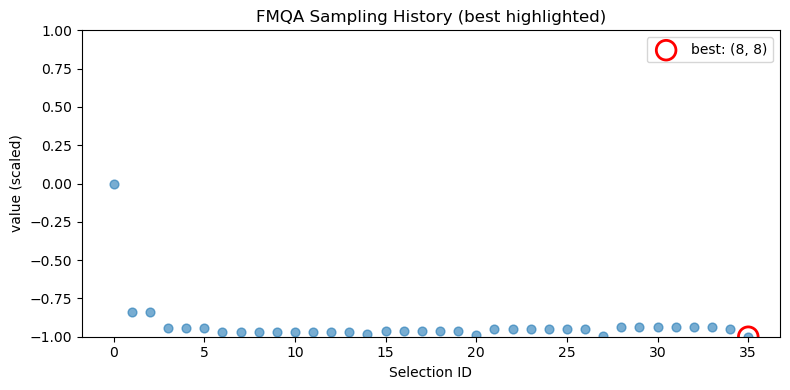


Trajectory of sampled (bitstring → coord → scaled objective) up to sample #36:
  sample  1 → 00010001 → (1, 1) → scaled obj = 0.0000
  sample  2 → 00100001 → (2, 1) → scaled obj = -0.8378
  sample  3 → 00100010 → (2, 2) → scaled obj = -0.8378
  sample  4 → 00110001 → (3, 1) → scaled obj = -0.9453
  sample  5 → 00110010 → (3, 2) → scaled obj = -0.9453
  sample  6 → 00110011 → (3, 3) → scaled obj = -0.9453
  sample  7 → 01000001 → (4, 1) → scaled obj = -0.9712
  sample  8 → 01000010 → (4, 2) → scaled obj = -0.9712
  sample  9 → 01000011 → (4, 3) → scaled obj = -0.9712
  sample 10 → 01000100 → (4, 4) → scaled obj = -0.9713
  sample 11 → 01010001 → (5, 1) → scaled obj = -0.9718
  sample 12 → 01010010 → (5, 2) → scaled obj = -0.9718
  sample 13 → 01010011 → (5, 3) → scaled obj = -0.9718
  sample 14 → 01010100 → (5, 4) → scaled obj = -0.9718
  sample 15 → 01010101 → (5, 5) → scaled obj = -0.9816
  sample 16 → 01100001 → (6, 1) → scaled obj = -0.9616
  sample 17 → 01100010 → (6, 2) → scaled 

In [22]:
# FMQA surrogate and sampling history

# Step 1: Build bit‐encoded design matrix and scaled objectives
x_max_idx, y_max_idx = max_x, max_y
keys = list(grid_data.keys())

X = np.array([
    [int(b) for b in coord_bits(x, y, x_max_idx, y_max_idx, lsb_first=False)]
    for x, y in keys
], dtype=int)

y = np.array([
    scale_point(x, y, grid_data, x_min, x_max)
    for x, y in keys
], dtype=float)

# Train FMQA model
model = FMBQM.from_data(X, y)
sampler = dimod.SimulatedAnnealingSampler()

# Keep histories
history_coords = keys.copy()
history_y = y.tolist()
history_bits = [  # initial binary encodings
    ''.join(str(bit) for bit in row)
    for row in X
]

# Bit lengths
nbit_x = int(np.ceil(np.log2(x_max_idx + 1)))
nbit_y = int(np.ceil(np.log2(y_max_idx + 1)))
total_bits = nbit_x + nbit_y

# Sampling loop
for _ in range(5):
    res = sampler.sample(model, num_reads=10)
    bits_arr = res.record['sample']
    
    new_y = []
    new_coords = []
    new_bitstrings = []
    valid_bits = []

    for bits in bits_arr:
        bx = bits[:nbit_x]
        by = bits[nbit_x:nbit_x + nbit_y]
        bitstring = ''.join(str(b) for b in bits)

        xi = int(''.join(str(b) for b in bx), 2)
        yi = int(''.join(str(b) for b in by), 2)
        coord = (xi, yi)

        if coord in grid_data and not np.isnan(grid_data[coord]):
            # Save only valid samples
            valid_bits.append(bits)
            new_coords.append(coord)
            new_y.append(scale_point(xi, yi, grid_data, x_min, x_max))
            new_bitstrings.append(bitstring)
        else:
            print(f"Skipping invalid sample {bitstring} → {coord}")

    # Extend histories with valid entries
    history_coords.extend(new_coords)
    history_y.extend(new_y)
    history_bits.extend(new_bitstrings)

    # Retrain on valid bit rows
    if valid_bits:
        X = np.vstack([X, valid_bits])
        y = np.hstack([y, new_y])
        model.train(X, y)

# Find the best result
best_idx = int(np.argmin(history_y))
best_coord = history_coords[best_idx]
best_val = history_y[best_idx]
best_bitstring = history_bits[best_idx]

print(f"\n→ Best sample #{best_idx}:")
print(f"   Bitstring = {best_bitstring}")
print(f"   Coord     = {best_coord}")
print(f"   Scaled val= {best_val:.4f}")

# Plot history
plt.figure(figsize=(8, 4))
plt.scatter(range(len(history_y)), history_y, s=40, alpha=0.6)
plt.scatter([best_idx], [best_val], s=200,
            facecolors='none', edgecolors='red', linewidths=2,
            label=f"best: {best_coord}")
plt.xlabel("Selection ID")
plt.ylabel("value (scaled)")
plt.ylim([-1, 1])
plt.legend()
plt.title("FMQA Sampling History (best highlighted)")
plt.tight_layout()
plt.show()

# Show trajectory of sampled coords and bitstrings
print("\nTrajectory of sampled (bitstring → coord → scaled objective) up to sample #36:")
for i in range(min(36, len(history_coords))):
    print(f"  sample {i+1:2d} → {history_bits[i]} → {history_coords[i]} → scaled obj = {history_y[i]:.4f}")

n_init = len(keys)
print(f"\nSampled points after initial {n_init} training points:")
for idx in range(n_init, len(history_coords)):
    print(f"sample {idx+1:2d} → {history_bits[idx]} → {history_coords[idx]}")


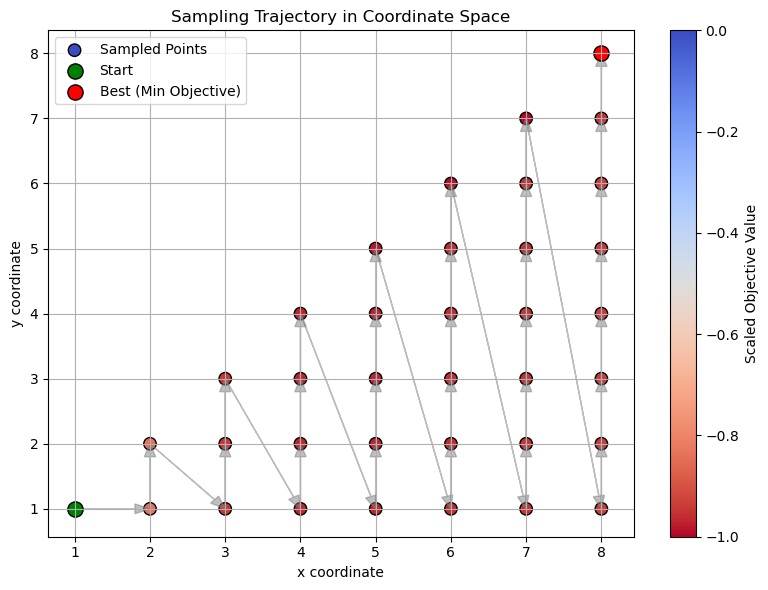

In [23]:
from matplotlib.ticker import MaxNLocator

# Extract X and Y from sampled coordinates
x_coords = [coord[0] for coord in history_coords]
y_coords = [coord[1] for coord in history_coords]
objectives = history_y

# Identify best (minimum objective) sample
best_idx = int(np.argmin(objectives))
best_coord = history_coords[best_idx]

plt.figure(figsize=(8, 6))

# Plot sampled points as scatter
sc = plt.scatter(x_coords, y_coords, c=objectives, cmap='coolwarm_r', s=80, edgecolors='k', label='Sampled Points')

# Draw trajectory arrows
for i in range(1, len(history_coords)):
    x_prev, y_prev = history_coords[i - 1]
    x_curr, y_curr = history_coords[i]
    plt.arrow(x_prev, y_prev, x_curr - x_prev, y_curr - y_prev,
              length_includes_head=True, head_width=0.15, head_length=0.2,
              fc='gray', ec='gray', alpha=0.5)

# Mark first point
plt.scatter(x_coords[0], y_coords[0], color='green', s=120, edgecolors='k', label='Start')

# Mark best (minimum) point
plt.scatter(best_coord[0], best_coord[1], color='red', s=120, edgecolors='k', label='Best (Min Objective)')

# Force integer ticks on both axes
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))

# Labels and styling
plt.xlabel("x coordinate")
plt.ylabel("y coordinate")
plt.title("Sampling Trajectory in Coordinate Space")
plt.colorbar(sc, label="Scaled Objective Value")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()